<a href="https://colab.research.google.com/github/inmira/Forecasting/blob/main/demand_forecasting_v4_explained.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Demand Forecasting for E-commerce (Olist) — v3

**Goal:** forecast daily demand (number of ordered item lines) for the next 14 days at product-category level, evaluate the models with time-based backtesting, and create a final 14-day forecast.

This notebook is based on v2, with additional data-quality checks, safer category selection, stronger features, corrected fold-level evaluation, and a reproducible future-forecast section.

## What was improved in v3

| Area | v3 improvement | Why it matters |
|---|---|---|
| Category selection | Top categories are selected using only the first training period | Avoids using future demand to decide which categories are modelled separately |
| Data preparation | Join validation, duplicate checks, missing-category report, order-status overview | Makes the target and data quality more transparent |
| Features | Additional lag, rolling median/std, and cyclical calendar features | Gives the models more information about recent level, variability, and seasonality |
| Random Forest | One-hot encoding for category instead of integer category codes | Avoids creating a false numeric order between categories |
| Backtesting | Fold-level metrics are grouped by the actual forecast origin | Shows stability across the eight test windows, not just calendar months |
| Forecasting | Adds a final forecast for the 14 days after the last observed date | Turns the evaluation notebook into a usable forecasting workflow |
| Prediction interval | Uses out-of-fold errors and labels the interval as empirical | Avoids presenting a simple residual band as a guaranteed confidence interval |
| Cold start | Renames the equal-share estimate and explains its limitation | Avoids presenting a category average as a true SKU-level prediction |

**Important target definition:** demand is the number of item lines in `order_items`, grouped by `order_purchase_timestamp`. All order statuses are included. This is a measure of *ordered items*, not necessarily delivered or retained sales. If the business question is delivered demand, the target definition must be changed before modelling.

**Forecasting setup:** each target date is predicted using information available at least 14 days before that target date. This is a conservative fixed-lead feature design. It avoids future leakage, but it deliberately does not use the most recent 13 days of history for the earliest day in each 14-day test window.

## 1. Setup

In [1]:
%pip install -q holidays lightgbm gdown statsmodels

In [2]:
import os
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
import lightgbm as lgb

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (12, 4)

# Main experiment settings
HORIZON = 14
N_FOLDS = 8
TOP_N = 8
START_DATE = "2017-01-01"
END_DATE = "2018-08-20"  # keep the same cutoff as v2 for comparable results
SEED = 42

LAGS = [14, 21, 28, 35, 42, 56]
SEASONAL_LAGS = [14, 21, 28, 35]

assert min(LAGS) >= HORIZON, "All target-dependent lags must be at least the forecast lead."
print(f"Horizon: {HORIZON} days | Backtest folds: {N_FOLDS} | Top categories: {TOP_N}")

Horizon: 14 days | Backtest folds: 8 | Top categories: 8


## 2. Load the Olist data

The notebook uses the same Google Drive archive as v2. If `S_Data/` already exists in the Colab session, the download step is skipped.

If the download fails, upload/extract the Olist archive manually and make sure the four CSV files are available in `S_Data/`.

In [3]:
DATA_DIR = "S_Data"
ZIP_ID = "1Jk5ANQ6noxdeJv73zhfxUym3lyuoVMq6"

if not os.path.exists(f"{DATA_DIR}/orders.csv"):
    import gdown
    downloaded = gdown.download(
        f"https://drive.google.com/uc?id={ZIP_ID}",
        "olist_archive.zip",
        quiet=False
    )
    if downloaded is None or not os.path.exists("olist_archive.zip"):
        raise RuntimeError(
            "The archive could not be downloaded. Upload and extract the Olist archive into S_Data/."
        )
    with zipfile.ZipFile("olist_archive.zip") as zf:
        zf.extractall(".")

required_files = [
    "orders.csv",
    "order_items.csv",
    "products.csv",
    "product_category_name_translation.csv",
]
missing_files = [name for name in required_files if not os.path.exists(f"{DATA_DIR}/{name}")]
if missing_files:
    raise FileNotFoundError(f"Missing files in {DATA_DIR}/: {missing_files}")

orders = pd.read_csv(
    f"{DATA_DIR}/orders.csv",
    parse_dates=["order_purchase_timestamp"]
)
order_items = pd.read_csv(f"{DATA_DIR}/order_items.csv")
products = pd.read_csv(f"{DATA_DIR}/products.csv")
translation = pd.read_csv(
    f"{DATA_DIR}/product_category_name_translation.csv",
    encoding="utf-8-sig"
)

print("orders:", orders.shape)
print("order_items:", order_items.shape)
print("products:", products.shape)
print("translation:", translation.shape)

Downloading...
From (original): https://drive.google.com/uc?id=1Jk5ANQ6noxdeJv73zhfxUym3lyuoVMq6
From (redirected): https://drive.google.com/uc?id=1Jk5ANQ6noxdeJv73zhfxUym3lyuoVMq6&confirm=t&uuid=a215f286-0f3f-46f1-a920-40659315f482
To: /content/olist_archive.zip
100%|██████████| 45.0M/45.0M [00:00<00:00, 92.0MB/s]


orders: (99441, 8)
order_items: (112650, 7)
products: (32951, 9)
translation: (71, 2)


## 3. Data quality checks and target construction

Before joining the tables, check the keys and the order-status distribution. The target below includes **all** order statuses; the status table is displayed so that this decision is visible and can be reconsidered for a different business definition.

In [4]:
# Required columns
required_columns = {
    "orders": {"order_id", "order_purchase_timestamp"},
    "order_items": {"order_id", "product_id"},
    "products": {"product_id", "product_category_name"},
    "translation": {"product_category_name", "product_category_name_english"},
}
for table_name, required in required_columns.items():
    table = {
        "orders": orders,
        "order_items": order_items,
        "products": products,
        "translation": translation,
    }[table_name]
    missing = required - set(table.columns)
    if missing:
        raise ValueError(f"{table_name} is missing required columns: {missing}")

# Dimension keys should be unique for many-to-one joins.
print("Duplicate order_id in orders:", orders["order_id"].duplicated().sum())
print("Duplicate product_id in products:", products["product_id"].duplicated().sum())
print("Duplicate category key in translation:", translation["product_category_name"].duplicated().sum())

if orders["order_id"].duplicated().any():
    raise ValueError("orders.order_id is not unique; resolve duplicates before joining.")
if products["product_id"].duplicated().any():
    raise ValueError("products.product_id is not unique; resolve duplicates before joining.")
if translation["product_category_name"].duplicated().any():
    raise ValueError("Translation category keys are not unique; resolve duplicates before joining.")

if "order_status" in orders.columns:
    print("Order status distribution (all statuses are currently included):")
    display(
        orders["order_status"].value_counts(dropna=False)
        .rename_axis("order_status")
        .to_frame("orders")
    )

# Validate the order_items -> orders join and report unmatched item rows.
items = order_items[["order_id", "product_id"]].merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)
unmatched_order_rows = int((items["_merge"] != "both").sum())
items = items.loc[items["_merge"] == "both"].drop(columns="_merge")

# Add product category and English translation.
items = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one",
)
items = items.merge(
    translation,
    on="product_category_name",
    how="left",
    validate="many_to_one",
)

items["category"] = (
    items["product_category_name_english"]
    .fillna(items["product_category_name"])
    .fillna("unknown")
)
items["date"] = items["order_purchase_timestamp"].dt.normalize()

print(f"Unmatched order-item rows removed: {unmatched_order_rows:,}")
print(f"Rows after joins: {len(items):,}")
print(f"Missing product category before fallback: {items['product_category_name'].isna().mean():.2%}")
print(f"Unknown category after fallback: {(items['category'] == 'unknown').mean():.2%}")
print("Observed purchase-date range:", items["date"].min().date(), "->", items["date"].max().date())

Duplicate order_id in orders: 0
Duplicate product_id in products: 0
Duplicate category key in translation: 0
Order status distribution (all statuses are currently included):


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Unmatched order-item rows removed: 0
Rows after joins: 112,650
Missing product category before fallback: 1.42%
Unknown category after fallback: 1.42%
Observed purchase-date range: 2016-09-04 -> 2018-09-03


## 4. Daily demand and leak-free category selection

Demand is counted as the number of item rows per date and category. Calendar days without orders are filled with zero.

**Leakage fix:** the top categories are selected using only the initial training period, ending at the first backtest origin. The test-period demand is not used to decide which categories receive their own series.

### What the data checks tell us

The source tables contain 99,441 orders and 112,650 order-item rows. The join did not lose any order-item rows, and the key checks did not find duplicate order or product identifiers in the tables used here. About 1.42% of joined item rows have no translated product category; these are retained under the fallback category label rather than silently discarded.

The order-status distribution is strongly dominated by `delivered` orders (96,478). However, the current target deliberately includes every status, including canceled and unavailable orders. Consequently, the target measures **ordered item lines**, not completed deliveries or net sales. This distinction affects how the forecast should be interpreted.

The modelling period is restricted to 2017-01-01 through 2018-08-20. Although the source data contains later dates, the configured analysis window ends earlier so that the final 14-day period can be treated as a forecast horizon.

In [5]:
start = pd.Timestamp(START_DATE)
requested_end = pd.Timestamp(END_DATE)
observed_end = items["date"].max()
end = min(requested_end, observed_end)

if end < requested_end:
    print(
        f"WARNING: observed data ends on {observed_end.date()}, before configured END_DATE "
        f"{requested_end.date()}. The notebook will use {end.date()} as the end date."
    )

items = items[(items["date"] >= start) & (items["date"] <= end)].copy()
full_index = pd.date_range(start, end, freq="D")

daily_all = (
    items.groupby(["date", "category"])
    .size()
    .unstack(fill_value=0)
    .reindex(full_index, fill_value=0)
)
daily_all.index.name = "date"

first_origin = daily_all.index.max() - pd.Timedelta(days=HORIZON * N_FOLDS)
if first_origin <= daily_all.index.min() + pd.Timedelta(days=max(LAGS)):
    raise ValueError("Not enough history for the configured lags and backtest folds.")

initial_train = daily_all.loc[:first_origin]
top_categories = initial_train.sum().nlargest(TOP_N).index.tolist()
other_categories = [c for c in daily_all.columns if c not in top_categories]

# Keep the selected categories and aggregate the remaining categories into 'other'.
daily = daily_all[top_categories].copy()
daily["other"] = daily_all[other_categories].sum(axis=1) if other_categories else 0
daily["TOTAL"] = daily_all.sum(axis=1)
series_cols = top_categories + ["other"]

print("Daily date range:", daily.index.min().date(), "->", daily.index.max().date())
print("First backtest origin:", first_origin.date())
print("Categories selected using initial training data:", top_categories)
print("Number of categories grouped into 'other':", len(other_categories))
display(daily[series_cols + ["TOTAL"]].sum().sort_values(ascending=False).to_frame("items_in_period"))

Daily date range: 2017-01-01 -> 2018-08-20
First backtest origin: 2018-04-30
Categories selected using initial training data: ['bed_bath_table', 'sports_leisure', 'furniture_decor', 'health_beauty', 'computers_accessories', 'housewares', 'watches_gifts', 'telephony']
Number of categories grouped into 'other': 66


,items_in_period
category,
TOTAL,111238
other,48946
bed_bath_table,11016
health_beauty,9487
sports_leisure,8541
furniture_decor,8223
computers_accessories,7752
housewares,6840
watches_gifts,5932


## 5. Exploratory analysis and stationarity

### How to interpret the demand series

The daily total has an average of approximately 186 item lines and a median of 171. The mean being higher than the median suggests that some high-demand days pull the average upward. There are only four zero-demand days in the selected period, so the series is active on almost every calendar day.

The weekday profile is useful for checking whether demand follows a weekly pattern. Differences between weekday averages can justify including weekday and seasonal features, but the plot alone does not prove that a particular calendar effect causes demand changes.

The ADF test on the original level series gives a p-value of 0.0561. At the 5% significance level, this is not enough evidence to reject the unit-root null. After first differencing and weekly differencing, the p-values are below 0.05. This indicates that differencing removes much of the non-stationary behaviour detected by the test. It does not, by itself, establish that a particular SARIMA specification is optimal.

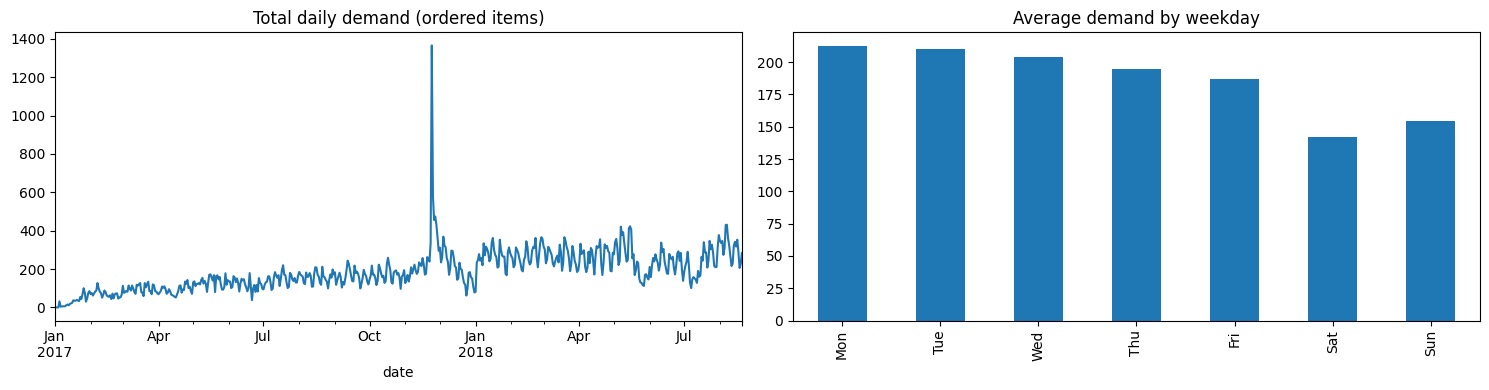

Average daily demand: 186.33
Median daily demand: 171.0
Zero-demand days: 4


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
daily["TOTAL"].plot(ax=axes[0], title="Total daily demand (ordered items)")
dow_mean = daily["TOTAL"].groupby(daily.index.dayofweek).mean()
dow_mean.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_mean.plot(kind="bar", ax=axes[1], title="Average demand by weekday")
plt.tight_layout()
plt.show()

print("Average daily demand:", round(daily["TOTAL"].mean(), 2))
print("Median daily demand:", round(daily["TOTAL"].median(), 2))
print("Zero-demand days:", int((daily["TOTAL"] == 0).sum()))

In [7]:
def adf_report(series, name):
    clean = series.dropna()
    statistic, p_value, *_ = adfuller(clean)
    conclusion = "Reject unit-root null at 5%" if p_value < 0.05 else "Cannot reject unit-root null at 5%"
    return {
        "series": name,
        "ADF statistic": statistic,
        "p-value": p_value,
        "interpretation": conclusion,
    }

adf_results = pd.DataFrame([
    adf_report(daily["TOTAL"], "level"),
    adf_report(daily["TOTAL"].diff(), "first difference"),
    adf_report(daily["TOTAL"].diff(7), "weekly difference (lag 7)"),
])
display(adf_results.round(4))

,series,ADF statistic,p-value,interpretation
0,level,-2.8154,0.0561,Cannot reject unit-root null at 5%
1,first difference,-10.0612,0.0000,Reject unit-root null at 5%
2,weekly difference (lag 7),-6.9353,0.0000,Reject unit-root null at 5%


**ADF interpretation:** the null hypothesis is that the series has a unit root. A p-value below 0.05 is evidence against that null. A p-value above 0.05 does not prove non-stationarity; it means the test did not reject the unit-root null at the 5% level. The ADF test is diagnostic and does not select SARIMA parameters automatically.

## 6. Feature engineering

For target date *t*, all demand-based features use observations no later than *t − 14*. The new features add longer lags, rolling medians and standard deviations, and cyclical calendar encodings.

The 14-day minimum lag is deliberately preserved. Do **not** add `lag_7` to this setup: it would use information from after the 14-day feature cutoff for some target dates.

In [8]:
def black_friday_date(year):
    """Black Friday: the Friday after the fourth Thursday in November."""
    november_1 = pd.Timestamp(year=year, month=11, day=1)
    first_thursday = november_1 + pd.Timedelta(days=(3 - november_1.dayofweek) % 7)
    fourth_thursday = first_thursday + pd.Timedelta(days=21)
    return fourth_thursday + pd.Timedelta(days=1)


def calendar_features(index):
    index = pd.DatetimeIndex(index)
    years = sorted(set(index.year))
    brazil_holidays = holidays.Brazil(years=years)
    black_fridays = {year: black_friday_date(year) for year in years}

    dow = index.dayofweek.to_numpy()
    month = index.month.to_numpy()
    day_of_year = index.dayofyear.to_numpy()
    days_in_year = np.where(index.is_leap_year, 366, 365)
    bf_delta = np.array([(date - black_fridays[date.year]).days for date in index])

    features = pd.DataFrame(index=index)
    features["dow"] = dow
    features["month"] = month
    features["dom"] = index.day.to_numpy()
    features["is_weekend"] = (dow >= 5).astype(int)
    features["is_month_start"] = index.is_month_start.astype(int)
    features["is_month_end"] = index.is_month_end.astype(int)
    features["is_holiday"] = [int(date in brazil_holidays) for date in index]
    features["bf_delta"] = np.clip(bf_delta, -14, 14)
    features["is_black_friday_window"] = ((bf_delta >= -3) & (bf_delta <= 3)).astype(int)

    # Cyclical encodings preserve the circular nature of calendar variables.
    features["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    features["dow_cos"] = np.cos(2 * np.pi * dow / 7)
    features["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    features["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
    features["doy_sin"] = np.sin(2 * np.pi * (day_of_year - 1) / days_in_year)
    features["doy_cos"] = np.cos(2 * np.pi * (day_of_year - 1) / days_in_year)
    return features


def make_training_features(daily_wide, categories, horizon=HORIZON):
    frames = []
    for category in categories:
        series = daily_wide[category].astype(float)
        frame = pd.DataFrame({"y": series})

        for lag in LAGS:
            frame[f"lag_{lag}"] = series.shift(lag)

        available_history = series.shift(horizon)
        frame["roll7_mean"] = available_history.rolling(7).mean()
        frame["roll28_mean"] = available_history.rolling(28).mean()
        frame["roll7_median"] = available_history.rolling(7).median()
        frame["roll28_std"] = available_history.rolling(28).std()
        frame["seas_mean4"] = frame[[f"lag_{lag}" for lag in SEASONAL_LAGS]].mean(axis=1)

        frame = frame.join(calendar_features(series.index))
        frame["category"] = category
        frames.append(frame)

    result = pd.concat(frames)
    result.index.name = "date"
    result = result.reset_index()

    numeric_features = [column for column in result.columns if column not in {"date", "category", "y"}]
    result = result.dropna(subset=["y"] + numeric_features).copy()
    return result


data = make_training_features(daily, series_cols)
NUM_FEATURES = [column for column in data.columns if column not in {"date", "category", "y"}]
FEATURES = NUM_FEATURES + ["category"]
data["category"] = pd.Categorical(data["category"], categories=series_cols)

print("Training rows:", len(data))
print("First usable target date:", data["date"].min().date())
print("Last usable target date:", data["date"].max().date())
print("Numeric features:", NUM_FEATURES)

Training rows: 4869
First usable target date: 2017-02-26
Last usable target date: 2018-08-20
Numeric features: ['lag_14', 'lag_21', 'lag_28', 'lag_35', 'lag_42', 'lag_56', 'roll7_mean', 'roll28_mean', 'roll7_median', 'roll28_std', 'seas_mean4', 'dow', 'month', 'dom', 'is_weekend', 'is_month_start', 'is_month_end', 'is_holiday', 'bf_delta', 'is_black_friday_window', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos']


In [9]:
# Small feature-safety checks on one category and one target date.
assert min(LAGS) >= HORIZON
sample_category = series_cols[0]
sample_date = data.loc[data["category"] == sample_category, "date"].iloc[0]
sample_row = data[(data["category"] == sample_category) & (data["date"] == sample_date)].iloc[0]

expected_lag14 = daily.loc[sample_date - pd.Timedelta(days=HORIZON), sample_category]
expected_roll7 = daily.loc[
    sample_date - pd.Timedelta(days=HORIZON + 6): sample_date - pd.Timedelta(days=HORIZON),
    sample_category
].mean()

assert np.isclose(sample_row["lag_14"], expected_lag14)
assert np.isclose(sample_row["roll7_mean"], expected_roll7)
print("Feature checks passed: lag_14 and roll7_mean use data no later than target_date - 14 days.")

Feature checks passed: lag_14 and roll7_mean use data no later than target_date - 14 days.


### Why these features are used

Lag features represent demand observed on earlier dates. Rolling statistics summarise recent history: the mean captures the average level, the median is less sensitive to unusually high days, and the rolling standard deviation describes variability. `seas_mean4` summarises the four most recent observations for the same weekday, giving the model a smoothed weekly reference.

Calendar features represent recurring timing patterns such as weekday, month, day of month, weekends and the Black Friday period. Sine/cosine encodings represent cyclical variables without creating an artificial jump between the end and beginning of a cycle.

The feature-safety check confirms that the tested lag and rolling features do not use observations later than the permitted cutoff of target date minus 14 days. This is essential: a feature can be predictive but invalid if it contains information that would not have been available at forecast time.

## 7. Models

The notebook compares the same tabular target and the same test dates across these models:

- **Seasonal naive:** demand on the same weekday 14 days earlier (`lag_14`).
- **Seasonal mean 4:** average of four previous same-weekday observations.
- **Ridge Regression:** regularised linear regression with one-hot category encoding and scaled numeric features.
- **Random Forest:** non-linear tree ensemble with one-hot category encoding.
- **LightGBM:** gradient-boosted trees with native categorical handling.
- **SARIMA and Holt-Winters:** classical models on total daily demand; evaluated at total level only.

Hyperparameters are fixed rather than tuned on the backtest folds. This keeps the evaluation easier to interpret and avoids tuning against the reported test results. Hyperparameter optimisation should use a separate time-based validation design.

In [10]:
def clip_nonnegative(values):
    return np.clip(np.asarray(values, dtype=float), 0, None)


def cap_training_target(train, quantile=0.99):
    """Winsorize y using category-specific quantiles from this training fold only."""
    caps = train.groupby("category", observed=True)["y"].transform(
        lambda values: values.quantile(quantile)
    )
    return np.minimum(train["y"].to_numpy(), caps.to_numpy())


def build_lightgbm():
    return lgb.LGBMRegressor(
        objective="regression",
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=SEED,
        n_jobs=-1,
        verbosity=-1,
    )


def fit_predict_seasonal_naive(train, test, winsor=False):
    return test["lag_14"].to_numpy()


def fit_predict_seasonal_mean4(train, test, winsor=False):
    return test["seas_mean4"].to_numpy()


def fit_predict_ridge(train, test, winsor=False):
    target = cap_training_target(train) if winsor else train["y"].to_numpy()
    preprocessor = ColumnTransformer([
        ("category", OneHotEncoder(handle_unknown="ignore"), ["category"]),
        ("numeric", StandardScaler(), NUM_FEATURES),
    ])
    model = make_pipeline(preprocessor, Ridge(alpha=10.0))
    model.fit(train[FEATURES], target)
    return clip_nonnegative(model.predict(test[FEATURES]))


def fit_predict_random_forest(train, test, winsor=False):
    target = cap_training_target(train) if winsor else train["y"].to_numpy()
    preprocessor = ColumnTransformer([
        ("category", OneHotEncoder(handle_unknown="ignore"), ["category"]),
        ("numeric", "passthrough", NUM_FEATURES),
    ])
    model = make_pipeline(
        preprocessor,
        RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=3,
            max_features=0.9,
            n_jobs=-1,
            random_state=SEED,
        ),
    )
    model.fit(train[FEATURES], target)
    return clip_nonnegative(model.predict(test[FEATURES]))


def fit_predict_lightgbm(train, test, winsor=False):
    target = cap_training_target(train) if winsor else train["y"].to_numpy()
    model = build_lightgbm()
    model.fit(train[FEATURES], target, categorical_feature=["category"])
    return clip_nonnegative(model.predict(test[FEATURES]))


TABULAR_MODELS = {
    "seasonal_naive": fit_predict_seasonal_naive,
    "seasonal_mean4": fit_predict_seasonal_mean4,
    "ridge": fit_predict_ridge,
    "random_forest": fit_predict_random_forest,
    "lightgbm": fit_predict_lightgbm,
}

### What the model comparison is designed to show

The seasonal-naive and seasonal-mean models provide simple reference points. They help answer whether more complex models add value beyond repeating or averaging previous same-weekday demand.

Ridge Regression tests whether a regularised linear relationship is sufficient. Random Forest and LightGBM can represent non-linear relationships and interactions between features. SARIMA and Holt-Winters provide classical time-series comparisons on the total daily series.

The comparison is meaningful because the models are evaluated on matching 14-day test windows and against the same total target. Model complexity alone is not evidence of quality; the backtest metrics determine whether the additional complexity improves forecasts.

## 8. Rolling-origin backtesting

Each fold has a 14-day test window. The model is trained on target dates up to the origin and evaluated on the next 14 dates. Origins are separated by 14 days, so the test windows do not overlap.

The category selection cutoff is the first origin. All folds use the same category list selected from that initial training period.

In [11]:
origins = [first_origin + pd.Timedelta(days=HORIZON * fold) for fold in range(N_FOLDS)]

print("Backtest windows:")
for origin in origins:
    test_start = origin + pd.Timedelta(days=1)
    test_end = origin + pd.Timedelta(days=HORIZON)
    print(f"  origin {origin.date()} -> test {test_start.date()} to {test_end.date()}")


def run_tabular_backtest(models, winsor=False):
    rows = []
    for origin in origins:
        train = data.loc[data["date"] <= origin].copy()
        test = data.loc[
            (data["date"] > origin) &
            (data["date"] <= origin + pd.Timedelta(days=HORIZON))
        ].copy()

        expected_rows = HORIZON * len(series_cols)
        if len(test) != expected_rows:
            raise ValueError(
                f"Unexpected test size at {origin.date()}: {len(test)} rows; expected {expected_rows}."
            )

        for model_name, fit_predict in models.items():
            predictions = fit_predict(train, test, winsor=winsor)
            if len(predictions) != len(test):
                raise ValueError(f"{model_name} returned {len(predictions)} predictions for {len(test)} rows.")

            rows.append(pd.DataFrame({
                "origin": origin,
                "date": test["date"].to_numpy(),
                "category": test["category"].astype(str).to_numpy(),
                "actual": test["y"].to_numpy(),
                "pred": predictions,
                "model": model_name,
            }))

    return pd.concat(rows, ignore_index=True)


backtest = run_tabular_backtest(TABULAR_MODELS)
display(backtest.head())

Backtest windows:
  origin 2018-04-30 -> test 2018-05-01 to 2018-05-14
  origin 2018-05-14 -> test 2018-05-15 to 2018-05-28
  origin 2018-05-28 -> test 2018-05-29 to 2018-06-11
  origin 2018-06-11 -> test 2018-06-12 to 2018-06-25
  origin 2018-06-25 -> test 2018-06-26 to 2018-07-09
  origin 2018-07-09 -> test 2018-07-10 to 2018-07-23
  origin 2018-07-23 -> test 2018-07-24 to 2018-08-06
  origin 2018-08-06 -> test 2018-08-07 to 2018-08-20


,origin,date,category,actual,pred,model
0,2018-04-30,2018-05-01,bed_bath_table,35.0,40.0,seasonal_naive
1,2018-04-30,2018-05-02,bed_bath_table,24.0,27.0,seasonal_naive
2,2018-04-30,2018-05-03,bed_bath_table,23.0,30.0,seasonal_naive
3,2018-04-30,2018-05-04,bed_bath_table,30.0,20.0,seasonal_naive
4,2018-04-30,2018-05-05,bed_bath_table,21.0,12.0,seasonal_naive


### How to read the backtest

There are eight consecutive, non-overlapping test windows. Each model is trained using information available at its forecast origin and evaluated on the following 14 days. This imitates repeated forecasting decisions through time more realistically than a random train/test split.

The first origin is 2018-04-30 and the last origin is 2018-08-06. The final test window therefore ends on 2018-08-20. The category list remains fixed across folds and was selected using only the initial training period. This avoids selecting categories based on later test-period demand, although it also means the category ranking is not recalculated at every fold.

### Classical models on total demand

SARIMA and Holt-Winters are fitted separately at each origin on the total daily series. They are compared with the tabular models only after category forecasts have been summed to the same total target.

In [12]:
total_series = daily["TOTAL"].astype(float)
classical_rows = []

for origin in origins:
    train_series = total_series.loc[:origin]
    test_dates = pd.date_range(origin + pd.Timedelta(days=1), periods=HORIZON, freq="D")
    actual = total_series.reindex(test_dates)

    try:
        sarima = SARIMAX(
            train_series,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False)
        sarima_prediction = clip_nonnegative(sarima.forecast(steps=HORIZON).to_numpy())
    except Exception as error:
        print(f"SARIMA failed at {origin.date()}: {error}")
        sarima_prediction = np.full(HORIZON, np.nan)

    try:
        holt_winters = ExponentialSmoothing(
            train_series.clip(lower=0.1),
            trend="add",
            damped_trend=True,
            seasonal="add",
            seasonal_periods=7,
        ).fit(optimized=True)
        hw_prediction = clip_nonnegative(holt_winters.forecast(HORIZON).to_numpy())
    except Exception as error:
        print(f"Holt-Winters failed at {origin.date()}: {error}")
        hw_prediction = np.full(HORIZON, np.nan)

    for model_name, predictions in [
        ("sarima", sarima_prediction),
        ("holt_winters", hw_prediction),
    ]:
        classical_rows.append(pd.DataFrame({
            "origin": origin,
            "date": test_dates,
            "category": "TOTAL",
            "actual": actual.to_numpy(),
            "pred": predictions,
            "model": model_name,
        }))

backtest_classical = pd.concat(classical_rows, ignore_index=True)
print("Failed forecasts by classical model:")
display(backtest_classical.groupby("model")["pred"].apply(lambda values: values.isna().sum()).to_frame("failed_predictions"))

Failed forecasts by classical model:


,failed_predictions
model,
holt_winters,0
sarima,0


## 9. Evaluation metrics

- **WAPE:** sum of absolute errors divided by total actual demand. It works when some daily observations are zero.
- **Bias:** sum of `(forecast − actual)` divided by total actual demand. Positive means over-forecasting; negative means under-forecasting.
- **MAE:** average absolute error in item lines per day.
- **RMSE:** root mean squared error; it penalises large misses more strongly.

MAPE is not used because zero actual values make it undefined or unstable.

In [13]:
def calculate_metrics(frame):
    error = frame["pred"].astype(float) - frame["actual"].astype(float)
    actual_total = frame["actual"].astype(float).sum()
    denominator = actual_total if actual_total != 0 else np.nan
    return pd.Series({
        "WAPE": error.abs().sum() / denominator,
        "Bias": error.sum() / denominator,
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
    })


# Category level: each category/date is an observation.
category_metrics = pd.DataFrame({
    model_name: calculate_metrics(group)
    for model_name, group in backtest.groupby("model")
}).T.sort_values("WAPE")

# Total level: sum all category predictions for each origin/date.
tabular_total = (
    backtest.groupby(["origin", "date", "model"], as_index=False)[["actual", "pred"]]
    .sum()
)
all_total = pd.concat([
    tabular_total,
    backtest_classical[["origin", "date", "model", "actual", "pred"]],
], ignore_index=True)

total_metrics = pd.DataFrame({
    model_name: calculate_metrics(group.dropna(subset=["pred"]))
    for model_name, group in all_total.groupby("model")
}).T.sort_values("WAPE")

print("CATEGORY LEVEL — all modelled categories together")
display(category_metrics.round(3))
print("TOTAL LEVEL — all models on the same total target")
display(total_metrics.round(3))

CATEGORY LEVEL — all modelled categories together


,WAPE,Bias,MAE,RMSE
lightgbm,0.297,-0.035,8.338,13.048
random_forest,0.307,-0.022,8.612,13.491
ridge,0.324,-0.077,9.102,14.409
seasonal_mean4,0.332,-0.032,9.314,14.850
seasonal_naive,0.388,-0.012,10.900,17.248


TOTAL LEVEL — all models on the same total target


,WAPE,Bias,MAE,RMSE
lightgbm,0.207,-0.035,52.283,69.368
random_forest,0.219,-0.022,55.425,73.834
sarima,0.234,0.058,59.138,74.188
seasonal_mean4,0.259,-0.032,65.364,83.735
ridge,0.260,-0.077,65.599,79.220
holt_winters,0.277,0.008,69.965,85.469
seasonal_naive,0.294,-0.012,74.384,95.946


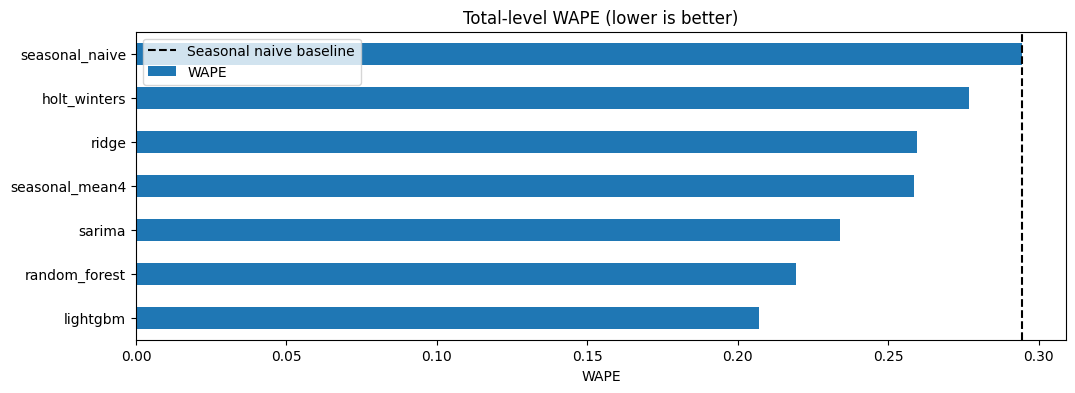

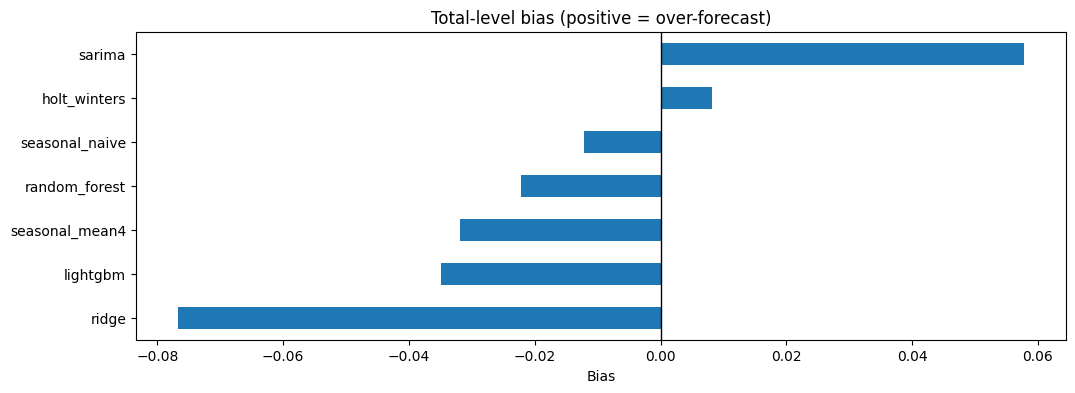

In [14]:
ax = total_metrics["WAPE"].sort_values().plot(kind="barh", title="Total-level WAPE (lower is better)")
ax.set_xlabel("WAPE")
if "seasonal_naive" in total_metrics.index:
    ax.axvline(total_metrics.loc["seasonal_naive", "WAPE"], color="black", linestyle="--", label="Seasonal naive baseline")
    ax.legend()
plt.show()

ax = total_metrics["Bias"].sort_values().plot(kind="barh", title="Total-level bias (positive = over-forecast)")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Bias")
plt.show()

### Overall model-comparison results

At the total-demand level, LightGBM has the lowest WAPE at **20.7%**, followed by Random Forest at **21.9%** and SARIMA at **23.4%**. The seasonal-naive baseline has a WAPE of **29.4%**. Relative to that baseline, LightGBM reduces WAPE by approximately **29.7%**.

LightGBM's bias is **-3.5%**, which indicates a modest overall under-forecast. Random Forest has a slightly smaller under-forecast at **-2.2%**, while SARIMA has a positive bias of **+5.8%**, indicating over-forecasting.

The category-level results show a similar ordering: LightGBM has the lowest combined WAPE (29.7%), followed by Random Forest (30.7%). Category-level WAPE is higher than total-level WAPE because errors are evaluated separately across the category series before aggregation. These are different evaluation views and should not be treated as interchangeable.

**Interpretation:** LightGBM is the strongest model by average WAPE in this backtest, and both tree-based models improve on the seasonal-naive baseline. The gap between LightGBM and Random Forest is relatively small, so stability across individual folds remains important.

## 10. Stability across backtest folds

This section groups results by the actual `origin` of each 14-day test window. It is not a monthly aggregation. A model can have the best average WAPE and still perform poorly in one or more individual windows.

model,holt_winters,lightgbm,random_forest,ridge,sarima,seasonal_mean4,seasonal_naive
origin,,,,,,,
2018-04-30,0.204,0.161,0.206,0.218,0.119,0.178,0.158
2018-05-14,0.618,0.533,0.554,0.449,0.550,0.498,0.626
2018-05-28,0.355,0.119,0.107,0.278,0.187,0.319,0.472
2018-06-11,0.150,0.118,0.109,0.125,0.112,0.081,0.184
2018-06-25,0.245,0.211,0.228,0.221,0.237,0.226,0.239
2018-07-09,0.387,0.248,0.256,0.309,0.336,0.291,0.367
2018-07-23,0.135,0.266,0.248,0.324,0.215,0.317,0.263
2018-08-06,0.237,0.063,0.099,0.184,0.201,0.207,0.173


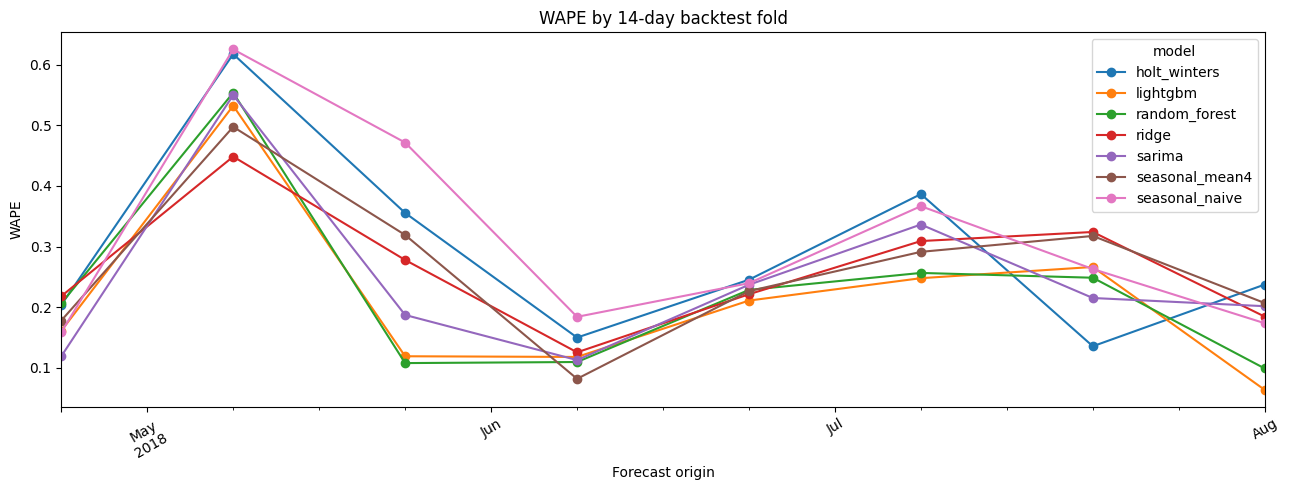

In [15]:
fold_rows = []
for (origin, model_name), group in all_total.groupby(["origin", "model"]):
    row = calculate_metrics(group.dropna(subset=["pred"]))
    row["origin"] = origin
    row["model"] = model_name
    fold_rows.append(row)

fold_metrics = pd.DataFrame(fold_rows)
fold_wape = fold_metrics.pivot(index="origin", columns="model", values="WAPE").sort_index()
display(fold_wape.round(3))

ax = fold_wape.plot(marker="o", figsize=(13, 5), title="WAPE by 14-day backtest fold")
ax.set_ylabel("WAPE")
ax.set_xlabel("Forecast origin")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 11. Forecast vs actual and category-level errors

### What fold stability reveals

The lowest-WAPE model changes across the eight test windows:
- 2018-04-30: SARIMA (11.9%)
- 2018-05-14: Ridge (44.9%)
- 2018-05-28: Random Forest (10.7%)
- 2018-06-11: Seasonal Mean 4 (8.1%)
- 2018-06-25: LightGBM (21.1%)
- 2018-07-09: LightGBM (24.8%)
- 2018-07-23: Holt-Winters (13.5%)
- 2018-08-06: LightGBM (6.3%)

LightGBM has the lowest WAPE in three of the eight folds, despite having the best overall WAPE. This means its aggregate advantage is not the same as winning every period. The second fold is particularly difficult for all models: WAPE ranges from 44.9% to 62.6%. That shared deterioration suggests that the period itself may have had an unusual demand pattern or level shift, rather than the issue being exclusive to one algorithm.

The fold results support using LightGBM as the current overall leader, but they also show that forecast quality varies materially over time. More backtest windows and an investigation of the difficult May 2018 window would make the stability assessment stronger.

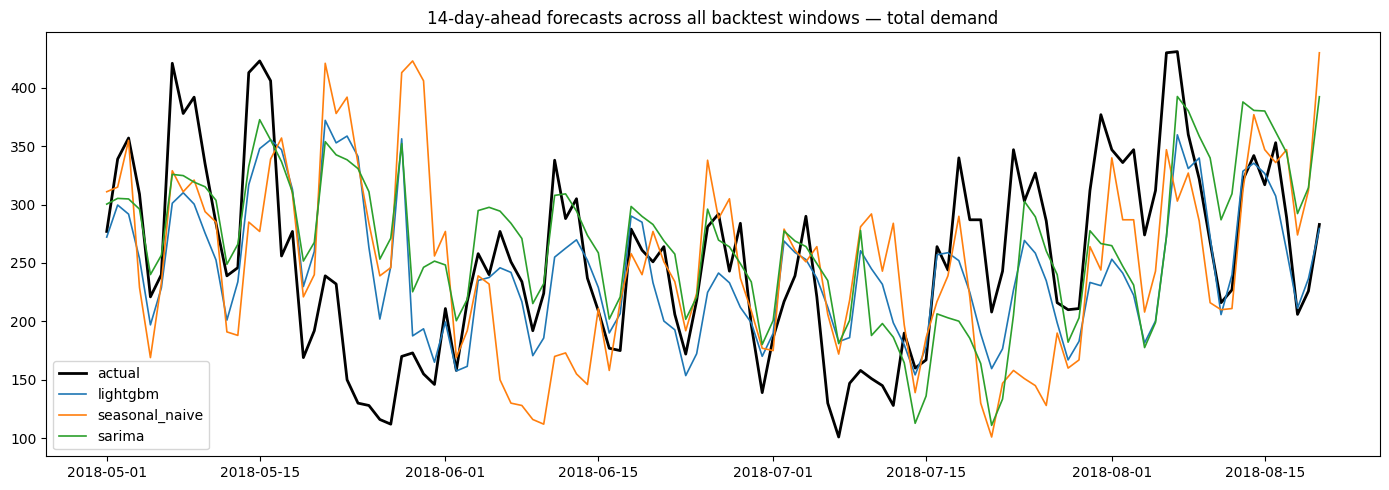

,WAPE,Bias,MAE,RMSE,volume_in_test
other,0.222,0.009,23.588,30.780,11902.0
health_beauty,0.342,-0.161,9.642,12.138,3156.0
bed_bath_table,0.289,-0.050,6.989,8.822,2711.0
housewares,0.382,-0.185,7.828,9.784,2297.0
watches_gifts,0.423,-0.053,7.578,10.040,2007.0
furniture_decor,0.335,-0.005,5.502,7.212,1841.0
sports_leisure,0.308,0.028,4.888,6.505,1780.0
computers_accessories,0.368,0.048,5.470,6.925,1664.0
telephony,0.422,-0.046,3.558,4.579,944.0


In [16]:
selected_models = [name for name in ["lightgbm", "seasonal_naive", "sarima"] if name in all_total["model"].unique()]
lightgbm_total = all_total[all_total["model"] == "lightgbm"].sort_values(["origin", "date"])

fig, ax = plt.subplots(figsize=(14, 5))
actual_unique = lightgbm_total.drop_duplicates(["origin", "date"])
ax.plot(actual_unique["date"], actual_unique["actual"], color="black", linewidth=2, label="actual")
for model_name in selected_models:
    model_frame = all_total[all_total["model"] == model_name].sort_values(["origin", "date"])
    ax.plot(model_frame["date"], model_frame["pred"], linewidth=1.2, label=model_name)
ax.set_title("14-day-ahead forecasts across all backtest windows — total demand")
ax.legend()
plt.tight_layout()
plt.show()

lightgbm_by_category = backtest[backtest["model"] == "lightgbm"].copy()
category_error_metrics = pd.DataFrame({
    category: calculate_metrics(group)
    for category, group in lightgbm_by_category.groupby("category")
}).T
category_error_metrics["volume_in_test"] = lightgbm_by_category.groupby("category")["actual"].sum()
category_error_metrics = category_error_metrics.sort_values("volume_in_test", ascending=False)
display(category_error_metrics.round(3))

## 12. Does winsorization help?

Winsorization is applied only to the **training target**, with a 99th-percentile cap calculated separately inside each training fold and category. The models are still scored against the original, uncapped test actuals.

### Category-level error interpretation

The category table compares errors across the eight backtest windows. `other` has the largest test volume (11,902 item lines) and a WAPE of 22.2%. Among the individually modelled categories, `bed_bath_table` has a WAPE of 28.9%, while `watches_gifts` and `telephony` are above 42%.

Some categories have negative bias, meaning demand is underestimated. For example, `health_beauty` has a bias of -16.1% and `housewares` has -18.5%. `sports_leisure` and `computers_accessories` have small positive biases, indicating slight over-forecasting.

These differences show why the total metric is not sufficient on its own. A model can perform reasonably well in aggregate while systematically missing demand in particular categories. The higher category-level errors may reflect smaller volumes, more volatile demand, or different category-specific patterns; the current analysis does not isolate which explanation is responsible.

In [17]:
winsor_models = {
    name: TABULAR_MODELS[name]
    for name in ["ridge", "random_forest", "lightgbm"]
}
backtest_winsor = run_tabular_backtest(winsor_models, winsor=True)
backtest_winsor["model"] = backtest_winsor["model"] + "_winsor"

winsor_total = (
    backtest_winsor.groupby(["origin", "date", "model"], as_index=False)[["actual", "pred"]]
    .sum()
)
winsor_metrics = pd.DataFrame({
    model_name: calculate_metrics(group)
    for model_name, group in winsor_total.groupby("model")
}).T

comparison_names = ["ridge", "random_forest", "lightgbm"]
comparison = pd.concat([
    total_metrics.loc[comparison_names],
    winsor_metrics,
]).sort_index()
display(comparison.round(3))

,WAPE,Bias,MAE,RMSE
lightgbm,0.207,-0.035,52.283,69.368
lightgbm_winsor,0.212,-0.049,53.663,70.009
random_forest,0.219,-0.022,55.425,73.834
random_forest_winsor,0.222,-0.033,56.204,74.204
ridge,0.260,-0.077,65.599,79.220
ridge_winsor,0.258,-0.077,65.185,78.831


## 13. LightGBM feature importance

Feature importance is descriptive, not causal. It shows which input features the fitted model used most often or found most useful under its split-gain criterion. Correlated lag and rolling features can share or exchange importance.

### Winsorization result

Winsorization caps unusually large values in the training target at the category-specific 99th percentile. The test targets are not capped, so the comparison still evaluates forecasts against the original observed demand.

For LightGBM, WAPE increases from **20.7% to 21.2%** after winsorization. Random Forest also becomes slightly worse, from **21.9% to 22.2%**. Ridge improves only marginally, from **26.0% to 25.8%**.

**Conclusion:** winsorization does not improve the two stronger tree-based models in this experiment. The small Ridge improvement is not enough to justify applying the transformation generally. For the current setup, the non-winsorized target is preferable.

,feature,gain_importance
10,seas_mean4,20655436.70
7,roll28_mean,18154271.65
4,lag_42,1983299.26
5,lag_56,1681795.54
8,roll7_median,1572622.87
24,doy_sin,1536182.03
26,category,1055239.95
11,dow,1028047.70
18,bf_delta,994647.29
25,doy_cos,910309.35


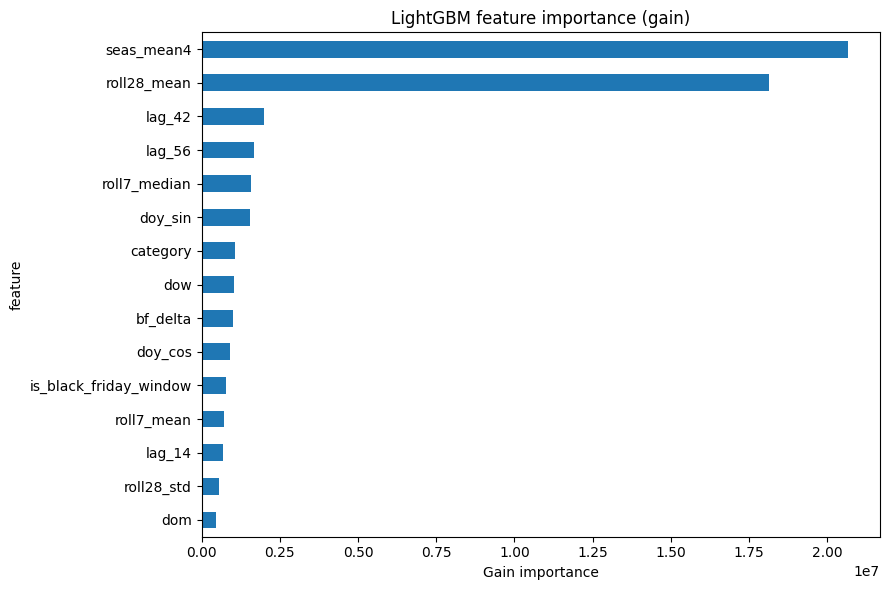

In [18]:
final_model = build_lightgbm()
final_model.fit(data[FEATURES], data["y"].to_numpy(), categorical_feature=["category"])

importance = pd.DataFrame({
    "feature": FEATURES,
    "gain_importance": final_model.booster_.feature_importance(importance_type="gain"),
})
importance = importance.sort_values("gain_importance", ascending=False)
display(importance.head(20).round(2))

plot_importance = importance.head(15).sort_values("gain_importance")
fig, ax = plt.subplots(figsize=(9, 6))
plot_importance.set_index("feature")["gain_importance"].plot(
    kind="barh", ax=ax, title="LightGBM feature importance (gain)"
)
ax.set_xlabel("Gain importance")
fig.tight_layout()
plt.show()

## 14. Empirical prediction interval

A point forecast does not show the uncertainty around demand. The following interval uses historical out-of-fold residuals (`actual − forecast`).

For a simple backtest check, the first seven folds are used to estimate the 10th and 90th residual quantiles, and the last fold is used to check coverage. This is an **empirical 80% interval**, not a guarantee and not a formally calibrated conformal interval. The last fold contains only 14 daily observations, so coverage is noisy.

### Interpreting feature importance

The two largest gain-importance values belong to `seas_mean4` and `roll28_mean`. This suggests that the model relies heavily on a smoothed same-weekday reference and the longer rolling demand level. Longer lags (`lag_42`, `lag_56`), the short rolling median and cyclical day-of-year features also contribute.

This pattern is consistent with demand being explained partly by recurring weekly behaviour and the recent overall level. It does not prove that these features cause demand, and it does not mean that the feature with the highest gain would be equally important in another model or time period. Correlated features can share importance.

Feature importance is therefore useful for understanding model behaviour and guiding further experiments, but it should not be interpreted as a causal analysis.

Residual quantiles from earlier folds: q10=-88.04, q90=92.88
Last-fold empirical interval coverage: 100.0% (14 days)


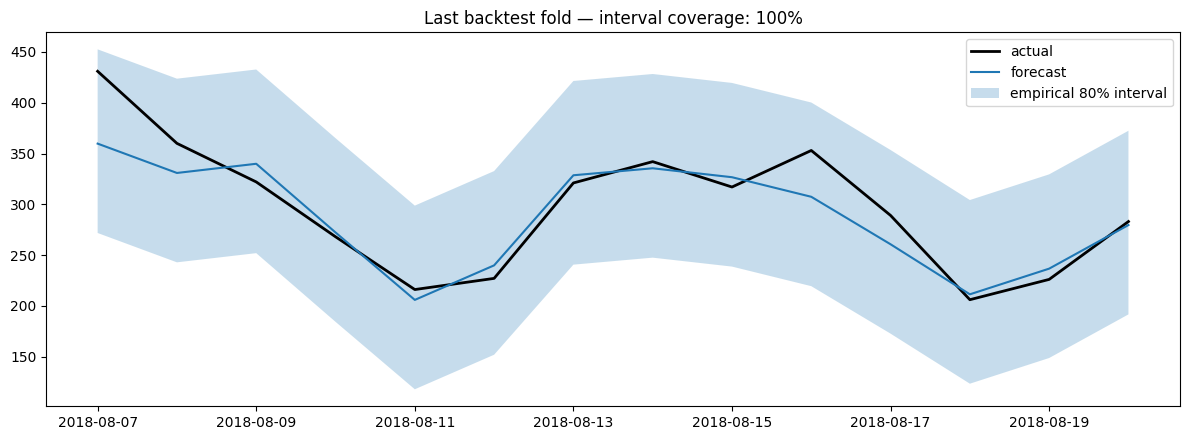

In [19]:
lightgbm_total = all_total[all_total["model"] == "lightgbm"].dropna(subset=["pred"]).copy()
lightgbm_total["residual"] = lightgbm_total["actual"] - lightgbm_total["pred"]
last_origin = origins[-1]

calibration_residuals = lightgbm_total.loc[
    lightgbm_total["origin"] < last_origin, "residual"
]
q10_prior, q90_prior = calibration_residuals.quantile([0.10, 0.90])
last_fold = lightgbm_total[lightgbm_total["origin"] == last_origin].copy()
last_fold["lower"] = np.maximum(0, last_fold["pred"] + q10_prior)
last_fold["upper"] = np.maximum(last_fold["lower"], last_fold["pred"] + q90_prior)
last_fold_coverage = (
    (last_fold["actual"] >= last_fold["lower"]) &
    (last_fold["actual"] <= last_fold["upper"])
).mean()

print(f"Residual quantiles from earlier folds: q10={q10_prior:.2f}, q90={q90_prior:.2f}")
print(f"Last-fold empirical interval coverage: {last_fold_coverage:.1%} ({len(last_fold)} days)")

tail = last_fold.sort_values("date")
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(tail["date"], tail["actual"], color="black", linewidth=2, label="actual")
ax.plot(tail["date"], tail["pred"], label="forecast")
ax.fill_between(tail["date"], tail["lower"], tail["upper"], alpha=0.25, label="empirical 80% interval")
ax.set_title(f"Last backtest fold — interval coverage: {last_fold_coverage:.0%}")
ax.legend()
plt.tight_layout()
plt.show()

## 15. Final forecast for the next 14 days

The model is refitted on all available labelled rows and predicts the 14 dates after the final observed date. For each future target date, the lag and rolling features are calculated from historical observations only; future actual demand is not used.

### What the empirical interval means

The residual quantiles estimated from the earlier folds are approximately **-88.04** and **+92.88** item lines. They are added to the point forecast to form a lower and upper empirical range.

The last fold has 100% coverage (14 out of 14 actual values fall inside the interval). This does not demonstrate that the interval is reliably calibrated: the check uses only 14 observations, and the interval is based on a small historical residual sample. The interval is also symmetric only approximately, because its lower and upper residual offsets differ.

Treat the band as an indication of historical forecast-error scale, not as a guaranteed 80% probability statement. A stronger assessment would measure coverage over multiple held-out folds and separately by forecast horizon.

In [20]:
def make_future_features(daily_wide, categories, future_dates, horizon=HORIZON):
    future_dates = pd.DatetimeIndex(future_dates)
    combined_index = daily_wide.index.union(future_dates).sort_values()
    frames = []

    for category in categories:
        series = daily_wide[category].astype(float).reindex(combined_index)
        frame = pd.DataFrame(index=future_dates)

        for lag in LAGS:
            frame[f"lag_{lag}"] = series.shift(lag).reindex(future_dates)

        available_history = series.shift(horizon)
        frame["roll7_mean"] = available_history.rolling(7).mean().reindex(future_dates)
        frame["roll28_mean"] = available_history.rolling(28).mean().reindex(future_dates)
        frame["roll7_median"] = available_history.rolling(7).median().reindex(future_dates)
        frame["roll28_std"] = available_history.rolling(28).std().reindex(future_dates)
        frame["seas_mean4"] = frame[[f"lag_{lag}" for lag in SEASONAL_LAGS]].mean(axis=1)

        frame = frame.join(calendar_features(future_dates))
        frame["category"] = category
        frames.append(frame)

    result = pd.concat(frames)
    result.index.name = "date"
    return result.reset_index()


last_observed_date = daily.index.max()
future_dates = pd.date_range(
    last_observed_date + pd.Timedelta(days=1),
    periods=HORIZON,
    freq="D",
)
future_features = make_future_features(daily, series_cols, future_dates)
future_features["category"] = pd.Categorical(
    future_features["category"], categories=series_cols
)

missing_future_features = future_features[NUM_FEATURES].isna().sum().sum()
if missing_future_features:
    raise ValueError(f"Future feature matrix contains {missing_future_features} missing values.")

# final_model was fitted on all historical labelled data in section 13.
future_predictions = clip_nonnegative(final_model.predict(future_features[FEATURES]))
future_by_category = future_features[["date", "category"]].copy()
future_by_category["forecast"] = future_predictions

future_total = (
    future_by_category.groupby("date", as_index=False)["forecast"]
    .sum()
    .rename(columns={"forecast": "forecast_total"})
)

# For a future forecast, use all historical out-of-fold residuals for the empirical error band.
all_oof_residuals = lightgbm_total["residual"]
q10_all, q90_all = all_oof_residuals.quantile([0.10, 0.90])
future_total["lower_empirical_80"] = np.maximum(0, future_total["forecast_total"] + q10_all)
future_total["upper_empirical_80"] = np.maximum(
    future_total["lower_empirical_80"],
    future_total["forecast_total"] + q90_all,
)

print("Forecast dates:", future_dates.min().date(), "->", future_dates.max().date())
print("Empirical residual offsets:", round(q10_all, 2), "to", round(q90_all, 2))
display(future_total.round(1))

Forecast dates: 2018-08-21 -> 2018-09-03
Empirical residual offsets: -85.62 to 91.21


,date,forecast_total,lower_empirical_80,upper_empirical_80
0,2018-08-21,292.9,207.3,384.1
1,2018-08-22,255.0,169.4,346.2
2,2018-08-23,233.5,147.8,324.7
3,2018-08-24,203.0,117.3,294.2
4,2018-08-25,178.0,92.4,269.2
5,2018-08-26,178.2,92.6,269.4
6,2018-08-27,246.8,161.1,338.0
7,2018-08-28,261.7,176.0,352.9
8,2018-08-29,260.7,175.0,351.9
9,2018-08-30,227.8,142.2,319.0


,total_14d,average_per_day
category,,
other,1236.88,88.35
health_beauty,364.18,26.01
bed_bath_table,331.01,23.64
housewares,282.18,20.16
furniture_decor,226.48,16.18
watches_gifts,225.41,16.10
sports_leisure,219.23,15.66
computers_accessories,215.29,15.38
telephony,157.59,11.26


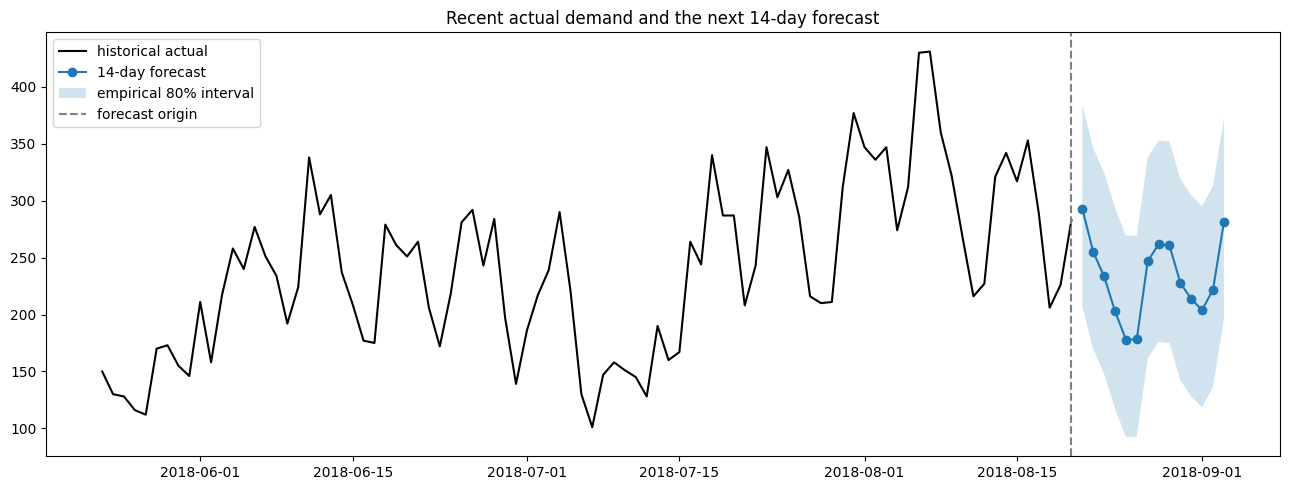

In [21]:
category_forecast_summary = (
    future_by_category.groupby("category")["forecast"]
    .agg(total_14d="sum", average_per_day="mean")
    .sort_values("total_14d", ascending=False)
)
display(category_forecast_summary.round(2))

history_window = daily["TOTAL"].tail(90)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(history_window.index, history_window.values, color="black", label="historical actual")
ax.plot(future_total["date"], future_total["forecast_total"], marker="o", label="14-day forecast")
ax.fill_between(
    future_total["date"],
    future_total["lower_empirical_80"],
    future_total["upper_empirical_80"],
    alpha=0.2,
    label="empirical 80% interval",
)
ax.axvline(last_observed_date, color="gray", linestyle="--", label="forecast origin")
ax.set_title("Recent actual demand and the next 14-day forecast")
ax.legend()
plt.tight_layout()
plt.show()

### Interpreting the 14-day category forecast

The forecast covers **2018-08-21 to 2018-09-03**, immediately after the final date used for model fitting. The largest forecast contribution comes from `other` (about 1,237 item lines over 14 days), followed by `health_beauty` (364) and `bed_bath_table` (331).

The `other` group combines all categories that were not selected for separate modelling, so its forecast is an aggregate of heterogeneous products. It should not be interpreted as one coherent product category.

The daily total forecast varies across the horizon, from approximately 178 to 293 item lines. The recurring variation is consistent with the model using calendar and weekday information. Because these dates are historical relative to the present, this output is a reconstruction of what the model would have forecast at the end of the dataset, not a current forecast.

## 16. Cold-start illustration for new products

A new product has no sales history. The simple allocation below divides the average daily forecast for a modelled category by the number of distinct products observed in that category during the previous 90 days.

This is an **equal-share baseline**, not a true product-level forecast. It assumes that products within a category have equal demand, which is unlikely in practice. The aggregated `other` group is excluded because it combines heterogeneous categories.

In [22]:
items["model_category"] = np.where(
    items["category"].isin(top_categories),
    items["category"],
    "other",
)
recent_start = last_observed_date - pd.Timedelta(days=90)
recent_items = items[
    (items["date"] > recent_start) &
    (items["date"] <= last_observed_date)
]
active_products = recent_items.groupby("model_category")["product_id"].nunique()

category_average_forecast = (
    future_by_category[future_by_category["category"] != "other"]
    .groupby("category")["forecast"].mean()
)
active_products = active_products.reindex(category_average_forecast.index)

cold_start = pd.DataFrame({
    "category_average_daily_forecast": category_average_forecast,
    "active_products_last_90d": active_products,
})
cold_start["equal_share_per_active_product"] = (
    cold_start["category_average_daily_forecast"] /
    cold_start["active_products_last_90d"].replace(0, np.nan)
)
display(cold_start.sort_values("category_average_daily_forecast", ascending=False).round(4))

,category_average_daily_forecast,active_products_last_90d,equal_share_per_active_product
category,,,
health_beauty,26.0129,961,0.0271
bed_bath_table,23.6439,1029,0.0230
housewares,20.1560,897,0.0225
furniture_decor,16.1773,631,0.0256
watches_gifts,16.1005,474,0.0340
sports_leisure,15.6593,726,0.0216
computers_accessories,15.3777,432,0.0356
telephony,11.2561,300,0.0375
other,NaN,4607,NaN


### Limits of the cold-start illustration

The table divides each category's average daily forecast by the number of distinct products observed in that category during the previous 90 days. For example, the estimated equal-share allocation is about 0.027 item lines per active product per day for `health_beauty` and 0.0375 for `telephony`.

These values are arithmetic averages, not predictions for individual products. They assume equal demand across products, while real product demand is usually uneven and affected by price, availability, age, reviews, promotions and product attributes. The `other` group is excluded from the allocation because it combines many different categories.

The calculation is useful only as a simple reference point when no product-level history is available. It should not be used as a validated SKU-level forecast.

## 17. Results and interpretation

The next cell collects the main metrics from the executed backtest. The values are calculated from the current notebook run, so they will update if the data or modelling configuration changes.

The interpretation should consider three things together:
1. **Average accuracy** — which model has the lowest WAPE across all backtest predictions.
2. **Stability** — whether the model performs consistently across the eight separate 14-day test windows.
3. **Direction of error** — whether the model tends to overestimate or underestimate demand.

A lower average WAPE does not automatically mean that a model is the best choice in every period. Fold-level results and bias are therefore considered alongside the overall metric.

In [23]:
baseline_wape = total_metrics.loc["seasonal_naive", "WAPE"]
best_model_name = total_metrics["WAPE"].idxmin()
best_model_wape = total_metrics.loc[best_model_name, "WAPE"]
best_model_bias = total_metrics.loc[best_model_name, "Bias"]
relative_improvement = (baseline_wape - best_model_wape) / baseline_wape

print(f"Baseline (seasonal naive) WAPE: {baseline_wape:.1%}")
print(f"Best model at total level: {best_model_name}")
print(f"Best-model WAPE: {best_model_wape:.1%}")
print(f"Best-model bias: {best_model_bias:+.1%}")
print(f"Relative WAPE reduction vs seasonal naive: {relative_improvement:.1%}")

if "lightgbm" in total_metrics.index and "lightgbm_winsor" in winsor_metrics.index:
    winsor_delta = winsor_metrics.loc["lightgbm_winsor", "WAPE"] - total_metrics.loc["lightgbm", "WAPE"]
    print(f"Change in LightGBM WAPE after target winsorization: {winsor_delta:+.4f} (negative is better)")

if "lightgbm" in fold_wape.columns:
    lightgbm_best_folds = int((fold_wape.idxmin(axis=1) == "lightgbm").sum())
    print(f"LightGBM has the lowest WAPE in {lightgbm_best_folds} of {len(fold_wape)} folds.")

print("\nInterpretation checklist:")
print("1. Compare the best model with the seasonal-naive baseline.")
print("2. Check whether the model is stable across folds, not only on average.")
print("3. Interpret bias: negative means under-forecasting; positive means over-forecasting.")
print("4. Keep winsorization only if it improves metrics on the raw test targets.")
print("5. Treat the empirical prediction interval and cold-start allocation as exploratory baselines.")

Baseline (seasonal naive) WAPE: 29.4%
Best model at total level: lightgbm
Best-model WAPE: 20.7%
Best-model bias: -3.5%
Relative WAPE reduction vs seasonal naive: 29.7%
Change in LightGBM WAPE after target winsorization: +0.0055 (negative is better)
LightGBM has the lowest WAPE in 3 of 8 folds.

Interpretation checklist:
1. Compare the best model with the seasonal-naive baseline.
2. Check whether the model is stable across folds, not only on average.
3. Interpret bias: negative means under-forecasting; positive means over-forecasting.
4. Keep winsorization only if it improves metrics on the raw test targets.
5. Treat the empirical prediction interval and cold-start allocation as exploratory baselines.


## 18. Export results

The following files are created in the current Colab working directory:

- `olist_forecast_next_14_days.csv` — total daily forecast and empirical interval.
- `olist_forecast_by_category_next_14_days.csv` — daily forecast by modelled category.
- `olist_backtest_predictions.csv` — out-of-fold predictions for the tabular models.
- `olist_model_metrics.csv` — total-level model comparison.

### Main conclusions from this run

1. **LightGBM gives the best overall result.** Its total-level WAPE is 20.7%, compared with 29.4% for the seasonal-naive baseline. This is an approximately 29.7% relative reduction in WAPE.
2. **Random Forest is a close second.** Its WAPE is 21.9%, only 1.2 percentage points above LightGBM. This small difference makes fold stability and operational simplicity relevant when comparing the two.
3. **The best average model is not the winner in every period.** LightGBM has the lowest WAPE in three of eight folds. The second fold is difficult for every model, indicating that the series contains periods that are hard to predict with the current feature set.
4. **The model slightly under-forecasts overall.** LightGBM bias is -3.5%. The error is not large at the aggregate level, but category-level bias is more pronounced in some categories, particularly `health_beauty` and `housewares`.
5. **Winsorization is not useful for the leading models here.** It increases WAPE for both LightGBM and Random Forest, so the original training target performs better in this experiment.
6. **The strongest features are seasonal and rolling summaries.** `seas_mean4` and `roll28_mean` have much higher gain importance than the remaining features, indicating that recent demand level and same-weekday history are important predictors.
7. **The empirical interval is preliminary.** Although it covers all 14 observations in the last fold, that sample is too small to establish reliable 80% coverage.
8. **The final forecast is historical.** It predicts 2018-08-21 through 2018-09-03 from the data available through 2018-08-20. It is not a forecast for the current date.

Overall, the current results support LightGBM as the best-performing model in this experiment, with Random Forest as a competitive alternative. The main weaknesses are uneven performance across folds, category-specific errors, the broad `other` group, and the limited evidence for prediction-interval calibration.

In [24]:
future_total.to_csv("olist_forecast_next_14_days.csv", index=False)
future_by_category.to_csv("olist_forecast_by_category_next_14_days.csv", index=False)
backtest.to_csv("olist_backtest_predictions.csv", index=False)
total_metrics.to_csv("olist_model_metrics.csv")

print("Exported files:")
for filename in [
    "olist_forecast_next_14_days.csv",
    "olist_forecast_by_category_next_14_days.csv",
    "olist_backtest_predictions.csv",
    "olist_model_metrics.csv",
]:
    print(" -", filename)

Exported files:
 - olist_forecast_next_14_days.csv
 - olist_forecast_by_category_next_14_days.csv
 - olist_backtest_predictions.csv
 - olist_model_metrics.csv


## 20. Limitations and next analytical steps

1. **Target definition:** the target counts ordered item rows and includes all order statuses. If the objective is delivered demand, construct a separate target using an explicit order-status rule and compare the results.
2. **Historical coverage:** the backtest contains eight 14-day folds (112 test days). It does not cover a full annual cycle or a complete Black Friday period.
3. **Category aggregation:** `other` combines heterogeneous categories and accounts for a large share of volume. Its aggregate forecast can hide very different patterns within the group.
4. **Fixed 14-day feature lead:** features use data no later than target date minus 14 days. This is leakage-safe, but it ignores the latest 13 days for the first day in each test window. Compare this design with a direct multi-horizon model using a common forecast origin and a `horizon_day` feature.
5. **External drivers:** promotions, price changes, stock availability, marketing campaigns and delivery constraints are not included. Their absence may explain some sudden changes that lag features cannot anticipate.
6. **Hyperparameter search:** parameters are fixed. If tuning is introduced, use a separate time-based validation process and preserve a final untouched test period.
7. **Prediction interval:** the empirical residual band is based on a limited sample. Evaluate coverage across several folds and by forecast horizon before treating it as calibrated.
8. **Cold start:** equal allocation across active products is only a simple baseline. A product-level model would need product attributes, price, category hierarchy and similar-product history.

### Recommended order of further experiments

- First, inspect the difficult 2018-05-15 to 2018-05-28 test window and determine whether the error is driven by a level shift, unusual category mix or data-quality issue.
- Second, compare alternative target definitions, especially all ordered item lines versus delivered item lines.
- Third, calculate errors separately for each day-ahead horizon (1 to 14) and check whether performance deteriorates later in the forecast window.
- Fourth, expand the backtest to more origins and a longer historical period where data permits.
- Fifth, test a direct multi-horizon setup and compare it with the current fixed-lead feature design.
- Finally, reassess interval coverage and category-level performance after the modelling changes.